# 第14章 Agent 入门

## 本章导读

第 8 章中，你修改 kernel、运行检查，再根据时间决定是否保留。现在把这件事交给 Agent：它怎样提出行动，怎样得到真实反馈？

本章先亲手调用一个小工具，观察错误与恢复。工具只计算任务的逻辑工作量；GPU 正确性与计时将在第 15 章接上。默认流程无需模型密钥。

前置：[第8章 notebook](../../part2-kernels/chapter8/chapter8.ipynb)。对照阅读：[本章正文](../../../docs/part3-agent/chapter14/index.md)。


In [ ]:
%run ../../common/bootstrap.py

import json
import pandas as pd
from IPython.display import display
import hello_gpu as gpu
from hello_gpu import agentlab
cfg = gpu.settings()
env = gpu.environment(require_gpu=False)
env


## 14.1 从一次手动优化说起

先核对向量加法的含义。每个输出只依赖同位置的两个输入；修改工作分配时，这个答案不能变化。运行后尝试修改一个输入，预测哪一个输出会改变。


In [ ]:
x = [1.0, -2.0, 0.5, 3.0]
y = [2.0, 4.0, -0.5, -1.0]
expected = [a + b for a, b in zip(x, y)]
display(pd.DataFrame({"x": x, "y": y, "正确输出 x+y": expected}))


**观察**：这个例子回答了“要算什么”。它没有测量 GPU 时间。优化需要在同一数学任务下提出改动、运行工具，再根据返回结果决定下一步。


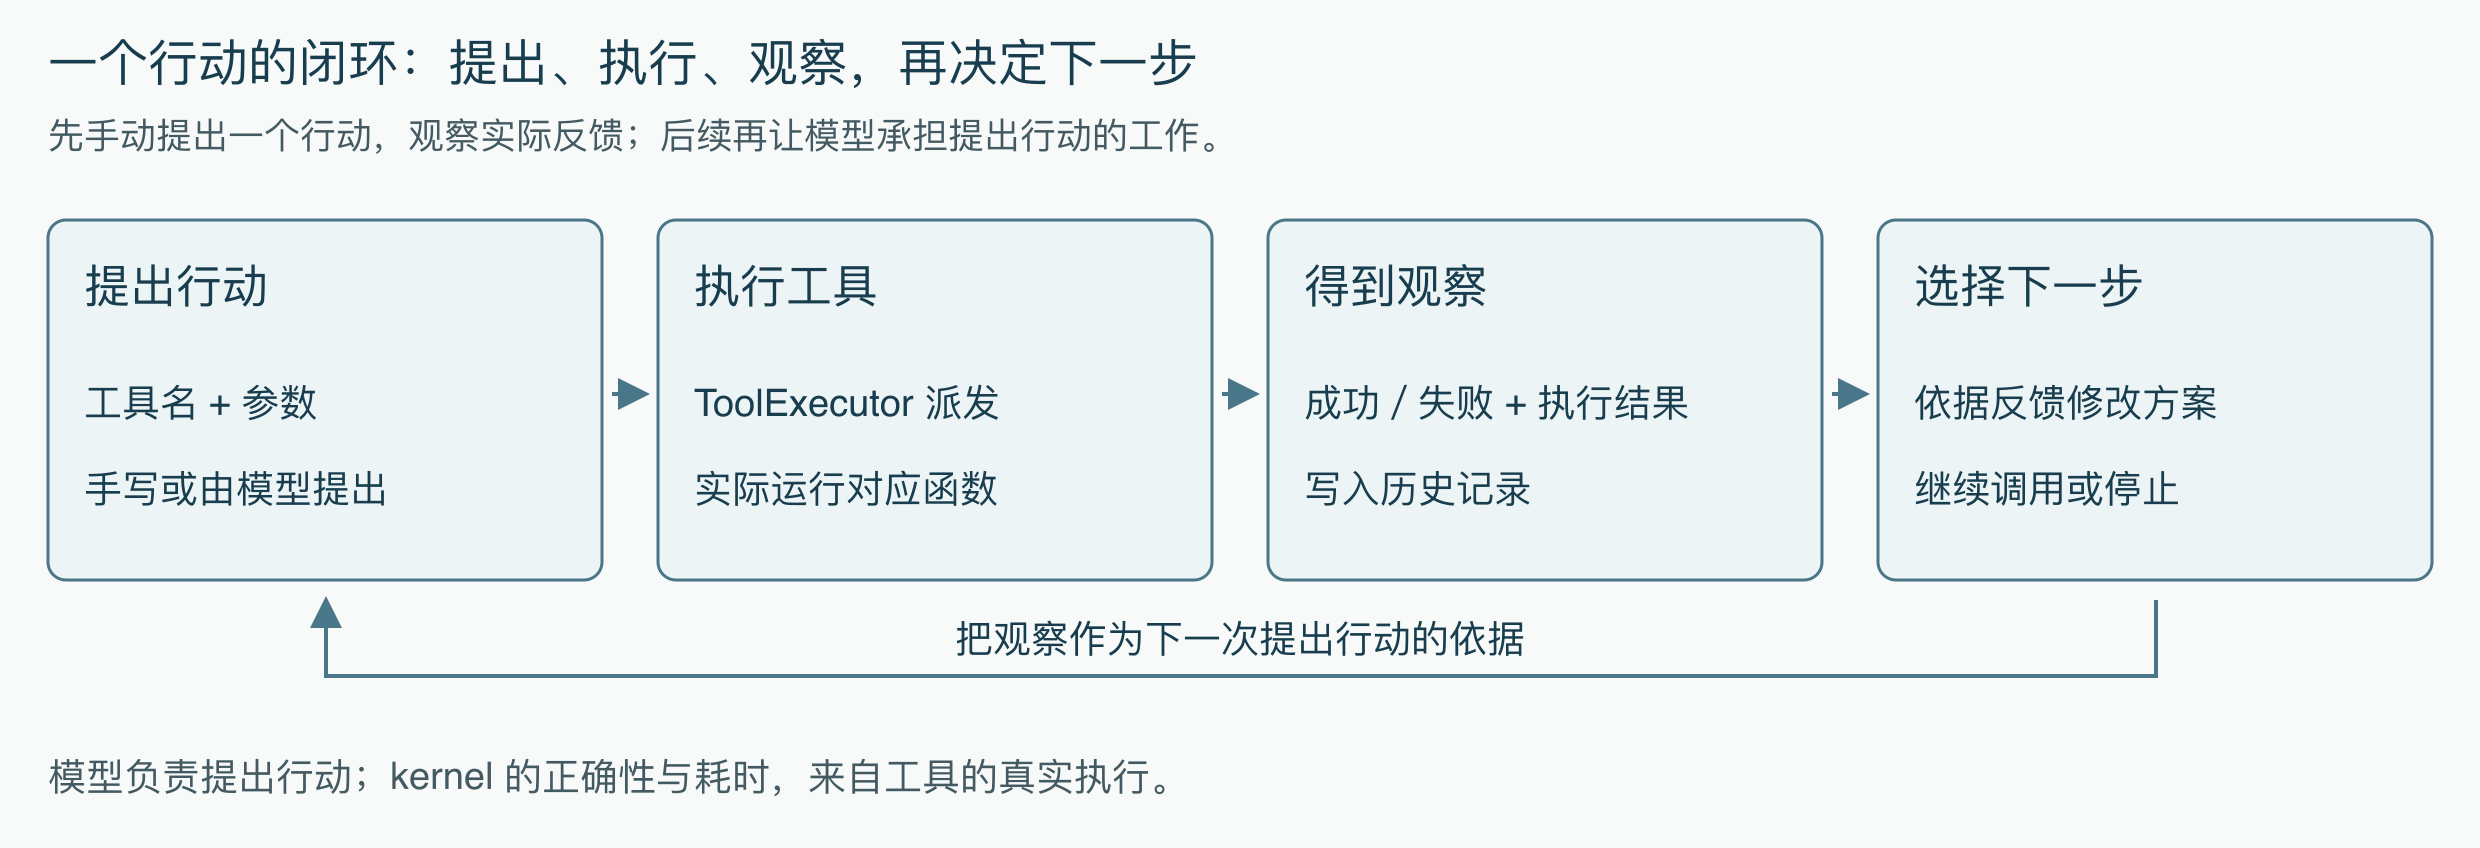

*行动来自学习者或模型，观察来自实际工具执行；下一步应依据返回结果。*


## 14.2 把算子优化拆成一个闭环

四章都使用 FP16 向量加法。我们固定输入规模、正确性容差和计时方式，只改变候选源码。先查看将交给工具的任务；这里的数量来自配置，性能结果要等真正运行之后才产生。


In [ ]:
task = agentlab.task_spec(cfg)
display(pd.Series({
    "元素数": task["tensors"][-1]["value"],
    "数据类型": task["tensors"][0]["dtype"],
    "调用入口": task["entrypoint"],
    "预热次数": task["benchmark"]["warmup"],
    "时间样本数": task["benchmark"]["samples"],
    "逻辑字节数": task["costModel"]["bytes"],
}))


规划者负责提出一个可检查的改动；工具负责对答案和测量；工作区负责保留任务、源码和记录。规划者说“应该更快”只是一个假设，不能替代工具输出。

## 14.3 理解 ReAct 与反思

ReAct 把推理（Reason）与行动（Act）连接起来。先写出一项具体假设，再决定需要调用什么工具。反思要说明观察支持了什么、还缺什么证据。


In [ ]:
hypothesis = {
    "改动": f"block_size 从 {cfg['block']} 改为 {cfg['block'] * 2}",
    "保持固定": "输入、数据类型、数学语义、计时方式",
    "先做什么": "检查答案，然后配对比较候选和当前实现",
    "尚未知道": "是否更快，以及变化是否由资源使用造成",
}
display(pd.Series(hypothesis))


**观察**：“block 变大”是行动计划；“快了多少”必须由测量回答。没有硬件资源证据时，也不能从速度变化直接推断寄存器或占用率变化。


## 14.4 模型怎样调用工具

先让你代替模型发出一次行动。下面注册的工具与后续 GPU 工具使用同一个 `ToolExecutor`。函数返回 JSON 文本，调度器根据名字和参数执行函数；参数检查写在函数中。


In [ ]:
tools = agentlab.ToolExecutor()
def describe_vector_add(elements):
    if not isinstance(elements, int) or isinstance(elements, bool) or elements < 1:
        raise ValueError("elements 必须是正整数")
    return json.dumps({"elements": elements, "flops": elements,
                       "logical_bytes": 3 * elements * 2}, ensure_ascii=False)

tools.register("describe_vector_add", "计算 FP16 加法的逻辑工作量",
               describe_vector_add,
               {"type": "object", "properties": {
                   "elements": {"type": "integer", "minimum": 1}},
                "required": ["elements"]})


In [ ]:
action = {"name": "describe_vector_add", "arguments": {"elements": 8}}
observation_text = tools.call(action["name"], action["arguments"])
observed = json.loads(observation_text)
display(pd.Series(observed, name="实际工具返回"))
assert observed["logical_bytes"] == 3 * action["arguments"]["elements"] * 2


把 `elements` 改成另一个正整数，再运行调用单元格。接着观察两种错误：工具名字不存在，以及参数不符合函数要求。错误也应成为可以读取的反馈。


In [ ]:
unknown_tool = tools.call("measure_speed_without_running", {})
bad_argument = tools.call("describe_vector_add", {"elements": -1})
display(pd.Series({"未知工具": unknown_tool, "非法参数": bad_argument}))
recovered = json.loads(tools.call("describe_vector_add", {"elements": 4097}))
assert recovered["elements"] == 4097
display(pd.Series(recovered, name="修复后的调用"))


**观察**：我们实际执行了函数，也读到了失败原因。工具说明告诉规划者怎样调用；函数实现负责执行和检查。模型接入后生成同样的行动结构，真实 GPU 时间仍由工具采集。


## 14.5 明确这套 Agent 能做什么

本篇的优化对象是固定任务中的 Triton 候选。第 8 章的 HIP 路线仍可用来理解同一个算子；当前 Agent 的候选检查和调用入口采用 Triton 合同。

本章由你手写行动，第 16–17 章会用预设策略演示自动循环，第 17 章另有显式开启的在线模型实验。预设策略不产生模型调用费用，也不等同于模型自主生成改动。我们不会预先保证任何配置提速。

## 14.6 练习：判断一份报告是否可信

先判断下面两句话，再运行自检：

- “这次工具计算了 4097 个元素的逻辑读写量。”
- “这份 kernel 更快，因为修改了 block。”

第一句能用工具返回值核对；第二句还缺正确性、相同条件下的测量和接受判定。请把缺少的证据写进你的报告。


In [ ]:
claim = "工具返回的 FP16 逻辑工作量"
assert recovered["logical_bytes"] == 3 * recovered["elements"] * 2
reflection = "修改配置后，要先验证，再配对比较；当前还没有 GPU 计时证据。"
print(claim, "：自检通过")
print("我的下一步：", reflection)


## 本章小结

你已亲手注册、调用和修复一个工具，并区分了计划与证据。下一章把同样的调用方式接到真实 kernel 检查和计时上。学完后，应能根据工具返回值修正行动，也能指出一份性能报告缺少什么。


## 延伸阅读

- [本章正文](../../../docs/part3-agent/chapter14/index.md)
- [Triton 向量加法教程](https://triton-lang.org/main/getting-started/tutorials/01-vector-add.html)
- [第15章 notebook](../chapter15/chapter15.ipynb)
